In [26]:
import numpy as np
from numpy.polynomial import chebyshev as cheb
from scipy import optimize
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import matplotlib as mpl
import matplotlib.cm as cm
from scipy.ndimage import zoom, gaussian_filter
import uuid
from numba import njit, prange
from numba_progress import ProgressBar
from scipy.stats import binned_statistic

# Force Modell

In [27]:
Lp = 1.5 # um Persistence length
kbT = 4.114
dt = 0.1010101
eps = 1e-14 # For numerical stability

In [28]:
def x_entropic_force(Fe):
    return 1 / np.tanh(2 * Lp * Fe / kbT) - kbT / (2 * Lp * Fe)

def dx_entropic_force(Fe):
    return 1 / (2 * Lp * Fe**2 / kbT) - 2 * Lp / kbT / np.sinh(2 * Lp * Fe / kbT)**2

In [29]:
def create_F(k, sample_density_x=1e-3, n_iter_equalize=5, x_max_full=5, cheb_subsampling = 16):
    
    ''' Creates a force curve for a given w.
        We return a chebychev polynomial that
        approximates the entire curve.

        From the experimental force rate w:
        k = w / v
    '''

    # Find F*, the transition from entropic to hookean force.
    res = optimize.root_scalar(lambda fe: dx_entropic_force(fe) - 1/k, bracket=(1e-12, 30))
    F_star = res.root

    # Determine the x range for forces to occur between 0 and F*
    x_min = x_entropic_force(sample_density_x)
    x_max = x_entropic_force(F_star)

    # Construct an even x grid of forces using the derivative of x
    n_x = max(int((x_max - x_min) / sample_density_x), 2)
    F  = np.linspace(1e-12, F_star, n_x)
    for _ in range(n_iter_equalize):
        cdx = np.cumsum(1/dx_entropic_force(F))
        cdx = cdx - cdx[0]
        cdx = cdx / cdx[-1]
        F = cdx * (F_star) + sample_density_x
    x = x_entropic_force(F)

    # The Hookean tail
    hook_tail_length = x_max_full - x_max
    xh = np.linspace(sample_density_x, hook_tail_length, int((hook_tail_length - sample_density_x) / sample_density_x))
    Fh = k * xh + F[-1]

    x = np.concatenate(([0], x, xh + x[-1]))
    F = np.concatenate(([0], F, Fh))

    C = cheb.Chebyshev.fit(x, F, len(x)//cheb_subsampling)
    
    return C, x, F

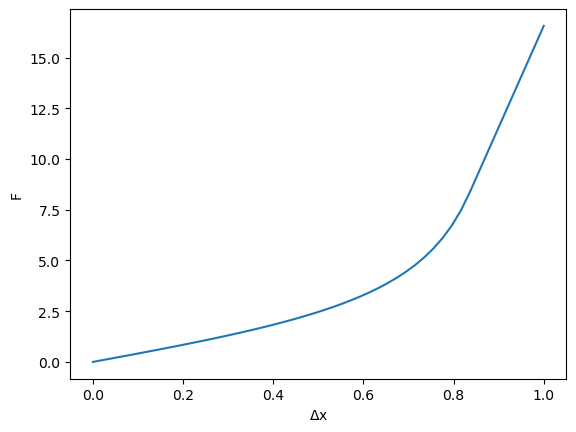

In [30]:
C, _, _ = create_F(50)
x = np.linspace(0, 1)
F = C(x)
plt.plot(x,F)
plt.xlabel("$\Delta$x")
plt.ylabel("F")
lut_x = np.linspace(0, 5, 10000)
lut_F = C(lut_x)

# Simulate Trajectories

In [31]:
@njit(parallel=True)
def generate_samples(N, ru, xu, v, lut_x, lut_F, dt, dropout_force=None, length=None, cache_length=10000):
    
    if dropout_force == None:
        dropout_force = -np.inf
        
    lut_size = lut_x.shape[0]
    lut_maxx = lut_x[-1]
    
    force = np.full((cache_length, N), np.nan)
    event = np.zeros(N)

    resets = 0

    for i in prange(N):
        t = 0
        while t < cache_length:
            x = v * t * dt
            if x >= lut_maxx:
                x = lut_maxx
            idx = int(lut_size * x / lut_maxx)
            f = lut_F[min(idx, lut_size-1)]
            force[t, i] = f

            pu = min(dt * ru * np.exp(f*xu/kbT), 1)
            a  = np.random.rand()
            if pu > a:
                if dropout_force > f:
                    force[:t, i] = np.nan
                    resets += 1
                    t = 0
                    continue
                else:
                    event[i] = t
                    break
            t += 1

    #print(resets/N)
    return force[:event.max(), :], event

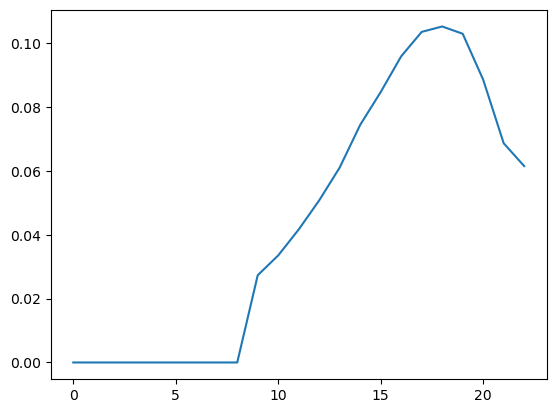

In [32]:
ru_GT = 0.15
xu_GT = 0.2
dropf_GT = 10
forces, event = generate_samples(100000, ru_GT, xu_GT, 1, lut_x, lut_F, dt, dropout_force=dropf_GT, cache_length=1000)

plen = np.histogram(event, bins=np.arange(event.max()))[0]
plen = plen / np.sum(plen)
plt.plot(plen)
logplen = np.log(plen + eps)

In [43]:
@njit(parallel=True)
def likelihood(logprior, ru, xu, forces_obs, event, dt, dropout_force):

    n_obs = forces_obs.shape[1]
    logpost = logprior

    for obs in prange(n_obs):

        len_f = int(event[obs]+1)
        f = forces_obs[:len_f, obs]
        rejects = np.sum(f < dropout_force)
        dropout_prob = rejects / len_f
        
        cump = 1
        p_dropout = 0
        
        for t in range(int(event[obs]+1)):
            F = forces_obs[t, obs]
            p = 1 - dt * ru * np.exp(F * xu / kbT)

            p_dropout += 1 / (1) * cump * (1-p) * (F < dropout_force)
            cump *= p
            
            if p > 1:
                p = 1
            if p < 0:
                p = 0
            if t  == event[obs]:
                p = 1 - p
                if F < dropout_force:
                    logpost += -np.inf

            logp = np.log(p+eps)
            logpost += logp

        logpost += - np.log(1-p_dropout)
            
    return logpost

# Observations

In [44]:
forces, event = generate_samples(68, ru_GT, xu_GT, 1, lut_x, lut_F, dt, dropout_force=dropf_GT, cache_length=1000)

In [45]:
likelihood(0, ru_GT, xu_GT, forces, event, dt, dropf_GT)

-175.43692060015724

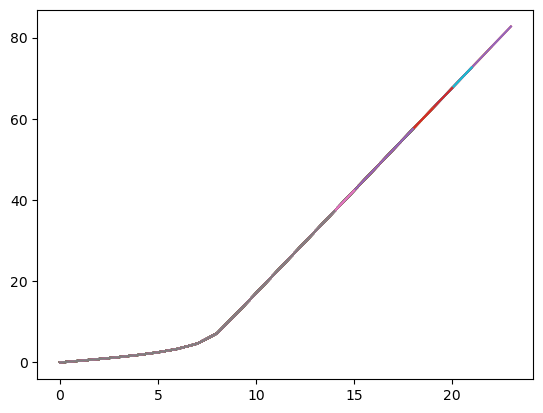

In [46]:
plt.plot(forces);

# Inference

In [47]:
n_samples = 500

ru = ru_GT
xu = xu_GT
dropf = 1*dropf_GT

RU = []
XU = []
DROPF = []

LOGL = -np.inf # Current chain likelihood

superstep = 1000
attempts = 0
accepts = 0
pbar = tqdm(range(n_samples * superstep))
for s in pbar:

    # GIBBS RU
    ru_prop = ru + np.random.randn() * 2e-3
    
    LOGL_prop = likelihood(0, ru_prop, xu, forces, event, dt, dropf)
    attempts += 1
    thresh = 1 if LOGL_prop > LOGL else np.exp(LOGL_prop - LOGL)
    a = np.random.rand()
    if a < thresh:
        accepts += 1
        LOGL = LOGL_prop
        ru = ru_prop

    # GIBBS XU
    xu_prop = xu + np.random.randn() * 2e-2
    
    LOGL_prop = likelihood(0, ru, xu_prop, forces, event, dt, dropf)
    attempts += 1
    thresh = 1 if LOGL_prop > LOGL else np.exp(LOGL_prop - LOGL)
    a = np.random.rand()
    if a < thresh:
        accepts += 1
        LOGL = LOGL_prop
        xu = xu_prop


    # GIBBS CUTOFF FORCE
    if False:
        dropf_prop = np.abs(dropf + np.random.randn() * 1e-1)
        LOGL_prop = likelihood(0, ru, xu, forces, event, dt, dropf_prop)
        attempts += 1
        thresh = 1 if LOGL_prop > LOGL else np.exp(LOGL_prop - LOGL)
        a = np.random.rand()
        if a < thresh:
            accepts += 1
            LOGL = LOGL_prop
            dropf = dropf_prop

    if not s % superstep:
        RU.append(ru)
        XU.append(xu)
        DROPF.append(dropf)
        pbar.set_description(f"Acceptance: {int(100*accepts/attempts)}%. Progress")

  0%|          | 0/500000 [00:00<?, ?it/s]

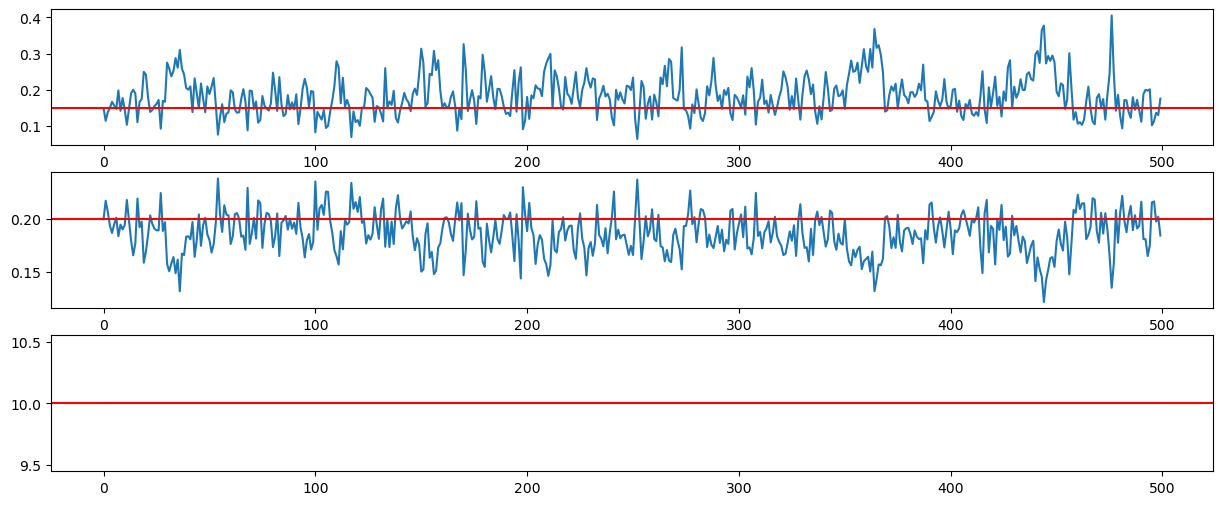

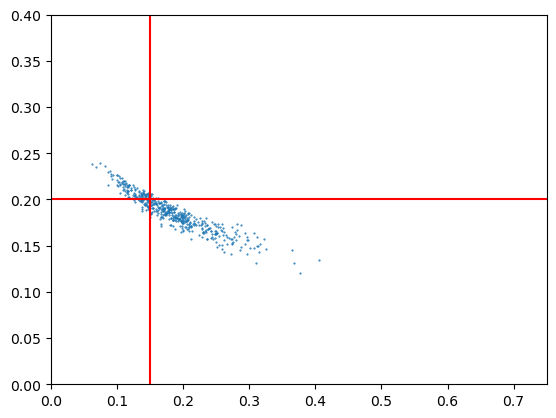

Text(0.5, 0, 'Rejection Threshold')

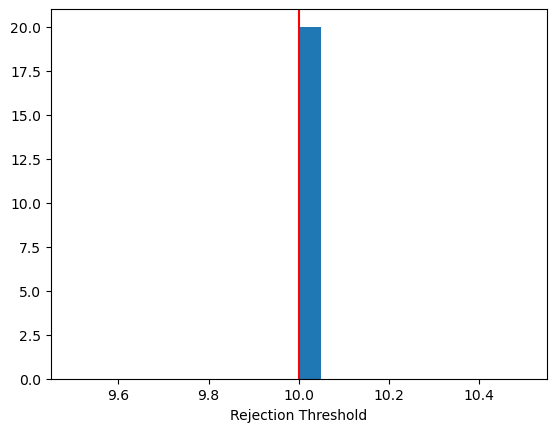

In [48]:
plt.figure(figsize=(15,6))
plt.subplot(3, 1, 1)
plt.plot(RU)
plt.axhline(ru_GT, c='r')
plt.subplot(3, 1, 2)
plt.plot(XU)
plt.axhline(xu_GT, c='r')
plt.subplot(3, 1, 3)
plt.plot(DROPF)
plt.axhline(dropf_GT, c='r')
plt.show()
plt.plot(RU, XU, '.', ms=1)
plt.xlim((0, 5*ru_GT))
plt.axvline(ru_GT, c='r')
plt.axhline(xu_GT, c='r')
plt.ylim((0, 2*xu_GT))
plt.show()
plt.hist(DROPF, bins=20, density=True);
plt.axvline(dropf_GT, c='r')
plt.xlabel("Rejection Threshold")